Following notebook displays the data, declares dataloaders classes and data distributions. As well as applying certain methods such as Data Augmentation or torchvision specific packages.

In [ ]:
from pathlib import Path
import copy
import numbers
import random
import time
import zipfile

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from PIL import Image
from skimage import io, transform, util, exposure

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils, models

from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
import torchvision.transforms.functional as TF
import timm

Before starting, we briefly describe the dataset and the classification task.

The aim of this project that you are embarking on is to develop a neural-network model for fire-risk classification. Forest fires threaten the environment, biodiversity and people's safety. Early detection and propagation modelling can support response planning; this particular assignment **predicts a** dataset's **risk category from a satellite image**, rather than performing fire detection or propagation forecasting.

The seven risk categories are:

- **Very Low:** areas where a fire is very unlikely to start or spread.
- **Low:** areas with low fire risk, although some factors could favour combustion under certain conditions.
- **Moderate:** areas with intermediate risk and potentially favourable conditions for fire spread.
- **High:** areas where a fire is likely to start and spread rapidly.
- **Very High:** areas with particularly favourable conditions for ignition and spread.
- **Non-burnable:** areas without enough combustible material to sustain a fire.
- **Water:** bodies of water.

The source dataset is described in:

Shen, S., Seneviratne, S., Wanyan, X., & Kirley, M. (2023, November). Firerisk: A remote sensing dataset for fire risk assessment with benchmarks using supervised and self-supervised learning. In *2023 International Conference on Digital Image Computing: Techniques and Applications (DICTA)* (pp. 189-196). IEEE.

Further information: [FireRisk repository](https://github.com/CharmonyShen/FireRisk).

For this assignment, a ZIP archive contains 5,861 selected RGB images and CSV files listing each split. The supplied images are **320 x 320 pixels**. The splits contain:

- **Training:** 3,516 images.
- **Validation:** 1,172 images.
- **Test:** 1,173 images.

Each CSV has a header and one row per image with two fields:

- `id`: the image identifier, used to construct the image filename.
- `label`: the class index for training and validation. Test labels are hidden and stored as `-1`.

The class indices and output-column order are fixed:

| Index | Class |
|---:|---|
| 0 | Water |
| 1 | Very Low |
| 2 | Low |
| 3 | Moderate |
| 4 | High |
| 5 | Very High |
| 6 | Non-burnable |

Use training and validation data to develop your system, then generate test predictions. This notebook provides a basic reference pipeline with three main components:

1. Read a custom dataset in PyTorch and implement data augmentation.
2. Build a feedforward convolutional network that maps images to seven class scores.
3. Fine-tune a network pretrained on a large, general-purpose image dataset.


In [ ]:
SEED = 42
CLASS_NAMES = ['Water', 'Very Low', 'Low', 'Moderate',
               'High', 'Very High', 'Non-burnable']
NUM_CLASSES = len(CLASS_NAMES)
MAX_TRAIN_SAMPLES = 0  # Set to 0 to use the full training split.
NUM_WORKERS = 0
CUSTOM_EPOCHS = 5
FT_EPOCHS = 5
CUSTOM_LR = 1e-2
FT_LR = 1e-3

# Note: PIXEL_MEAN and PIXEL_STD come directly from AlexNet's
# documentation in PyTorch:
# https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.alexnet.html
PIXEL_MEAN = [0.485, 0.456, 0.406]
PIXEL_STD = [0.229, 0.224, 0.225]

DATA_ARCHIVE = Path('db.zip')
DATA_ROOT = Path('data') if (Path('data') / 'db').is_dir() else Path('db')
DB_DIR = DATA_ROOT / 'db'
OUTPUT_DIR = Path('submissions')

In [ ]:
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything()
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'Class order: {CLASS_NAMES}')

Device: cuda:0
Class order: ['Water', 'Very Low', 'Low', 'Moderate', 'High', 'Very High', 'Non-burnable']


IF below cell has already been run, keep commented, if not uncomment the code.
It obtains the data from the zip file.

In [ ]:
required_csvs = [DB_DIR / f'{split}_reduced.csv'
                 for split in ('train', 'val', 'test')]

if DATA_ARCHIVE.is_file():
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    restored_files = 0
    with zipfile.ZipFile(DATA_ARCHIVE) as archive:

        for member in archive.infolist():
            if not member.filename.startswith('db/'):
                continue
            target = DATA_ROOT / member.filename
            if not member.is_dir() and target.is_file() and target.stat().st_size == member.file_size:
                continue
            if not target.resolve().is_relative_to(DATA_ROOT.resolve()):
                raise ValueError('The archive contains an invalid dataset path.')
            if member.is_dir():
                target.mkdir(parents=True, exist_ok=True)
            elif not target.is_file() or target.stat().st_size != member.file_size:
                archive.extract(member, DATA_ROOT)
                restored_files += 1
    print(f'Dataset ready at {DB_DIR.resolve()}; restored {restored_files} files.')

if not all(path.is_file() for path in required_csvs):
    raise FileNotFoundError(
        'Dataset CSV files were not found. Start the kernel in the notebook directory '
        'or update DATA_ARCHIVE and DATA_ROOT in the setup cell.')

for csv_path in required_csvs:
    ids = pd.read_csv(csv_path, usecols=['id'], dtype={'id': str})['id']
    for image_id in ids:
        image_path = DB_DIR / 'images' / f'{image_id}.jpg'
        if not image_path.is_file() or image_path.stat().st_size == 0:
            raise FileNotFoundError(
                f'Missing or empty image: {image_path}. Supply the original db.zip '
                'and rerun this setup cell to restore it.')

print('All indexed images exist and are nonempty.')

All indexed images exist and are nonempty.


In [ ]:
image_directory = DB_DIR / 'images'
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.tiff', '.webp'}
number_of_images = sum(path.is_file() and path.suffix.lower() in image_extensions
                       for path in image_directory.iterdir())

print(f'Number of images in {image_directory}: {number_of_images}')

Number of images in data\db\images: 5861


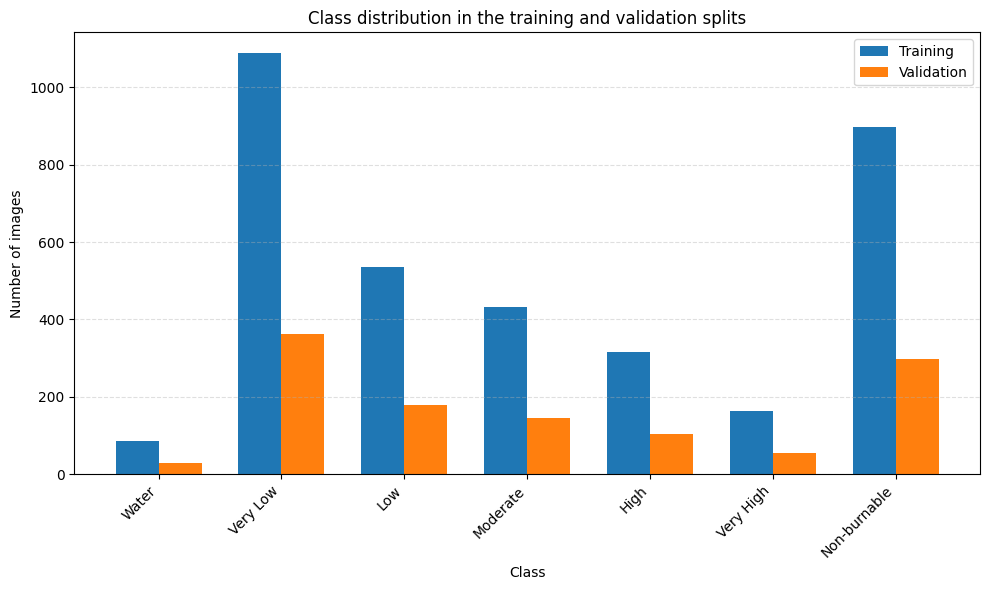

Training: 3516, validation: 1172, test: 1173


In [ ]:
# Count labelled images. Test labels are hidden, so no test class histogram is shown.

df_train = pd.read_csv(DB_DIR / 'train_reduced.csv', dtype={'id': str, 'label': int})
df_val = pd.read_csv(DB_DIR / 'val_reduced.csv', dtype={'id': str, 'label': int})
df_test = pd.read_csv(DB_DIR / 'test_reduced.csv', dtype={'id': str, 'label': int})

all_labels = np.arange(NUM_CLASSES)

train_counts = df_train['label'].value_counts().reindex(all_labels, fill_value=0)
val_counts = df_val['label'].value_counts().reindex(all_labels, fill_value=0)

for split_name, frame in [('training', df_train), ('validation', df_val)]:
    if frame.empty or not frame['label'].isin(all_labels).all():
        raise ValueError(f'The {split_name} split must have labels 0 through 6.')

if df_test.empty or not (df_test['label'] == -1).all():
    raise ValueError('The test split must be nonempty and have hidden labels (-1).')

if any(frame['id'].duplicated().any() for frame in (df_train, df_val, df_test)):
    raise ValueError('An index file contains duplicate image IDs.')

if (set(df_train['id']) & set(df_val['id']) or
    set(df_train['id']) & set(df_test['id']) or
    set(df_val['id']) & set(df_test['id'])):
    raise ValueError('Training, validation and test image IDs must be disjoint.')

x = np.arange(NUM_CLASSES)
width = 0.35
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width / 2, train_counts.to_numpy(), width, label='Training')
ax.bar(x + width / 2, val_counts.to_numpy(), width, label='Validation')
ax.set_xlabel('Class')
ax.set_ylabel('Number of images')
ax.set_title('Class distribution in the training and validation splits')
ax.set_xticks(x, CLASS_NAMES, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)
fig.tight_layout()
plt.show()
print(f'Training: {len(df_train)}, validation: {len(df_val)}, test: {len(df_test)}')

There is clearly a big class imbalance which should be accounted for when working with the model

### Preparing the dataset

Read the training index file and inspect example 100. Each row identifies an image and its class index:

`0 = Water`, `1 = Very Low`, `2 = Low`, `3 = Moderate`, `4 = High`, `5 = Very High`, `6 = Non-burnable`.

In [ ]:
### Preparing the dataset
db = pd.read_csv(DB_DIR / 'train_reduced.csv', dtype={'id': str, 'label': int})

n = min(100, len(db) - 1)
img_id = db.iloc[n]['id']
label = int(db.iloc[n]['label'])

print(f'Image ID: {img_id}')
print(f'Label: {label} ({CLASS_NAMES[label]})')

Image ID: 34574541
Label: 1 (Very Low)


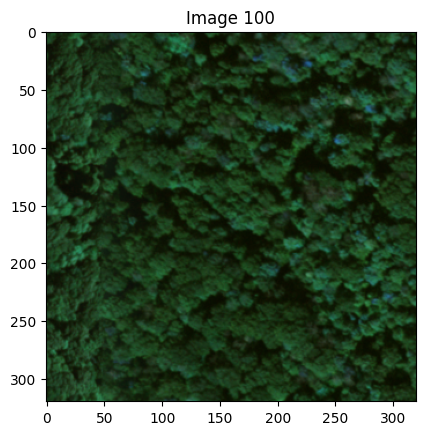

In [ ]:
def imshow(image, title_str):
    plt.imshow(image, cmap='gray' if image.ndim == 2 else None)
    plt.title(title_str)

plt.figure()
imshow(io.imread(DB_DIR / 'images' / f'{img_id}.jpg'), f'Image {n}')
plt.show()

### The Dataset class

`torch.utils.data.Dataset` is the abstract interface for a PyTorch dataset. Implement a subclass with:

- `__init__`: read the index and store configuration.
- `__len__`: return the number of samples.
- `__getitem__`: read and return a sample by index.

Read image files in `__getitem__`, rather than loading the entire image collection at construction time. This limits memory use.

Each sample is a dictionary: `{'image': image, 'label': label}`. The optional `transform` argument applies preprocessing and augmentation when a sample is requested. The class-name list is ordered by the numeric labels, so plot labels and output columns remain consistent.


In [ ]:
class FireRiskDataset(Dataset):
    """Read RGB images and integer labels using a CSV index.

    Args:
        csv_file: CSV with columns 'id' and 'label'.
        root_dir: Dataset directory containing the 'images' subdirectory.
        transform: Optional callable that receives and returns a sample dictionary.
        maxSize: Maximum subset size; 0 selects the full split.
    """

    def __init__(self, csv_file, root_dir, transform=None, maxSize=0):

        if not isinstance(maxSize, numbers.Integral) or maxSize < 0:
            raise ValueError('maxSize must be a nonnegative integer.')

        self.dataset = pd.read_csv(csv_file, dtype={'id': str, 'label': int})

        if not {'id', 'label'}.issubset(self.dataset.columns) or self.dataset.empty:
            raise ValueError('The CSV must contain nonempty id and label columns.')
        if not self.dataset['label'].isin(range(-1, NUM_CLASSES)).all():
            raise ValueError('Labels must be -1 (hidden test labels) or 0 through 6.')
        if maxSize > 0:
            indices = np.random.RandomState(SEED).permutation(len(self.dataset))
            self.dataset = self.dataset.iloc[indices[:maxSize]].reset_index(drop=True)

        self.img_dir = Path(root_dir) / 'images'
        self.transform = transform
        self.classes = CLASS_NAMES.copy()

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):

        if torch.is_tensor(idx):
            idx = idx.item()
        row = self.dataset.iloc[int(idx)]
        image = util.img_as_float32(io.imread(self.img_dir / f"{row['id']}.jpg"))

        if image.ndim == 2:
            image = np.repeat(image[..., None], 3, axis=2)
        elif image.ndim == 3 and image.shape[2] == 4:
            image = image[..., :3]
        if image.ndim != 3 or image.shape[2] != 3:
            raise ValueError('Expected an RGB image with three channels.')
        sample = {'image': image, 'label': int(row['label'])}

        return self.transform(sample) if self.transform is not None else sample

Instatiate the dataset and display a few samples.

0 (320, 320, 3) 0
1 (320, 320, 3) 0
2 (320, 320, 3) 0
3 (320, 320, 3) 0


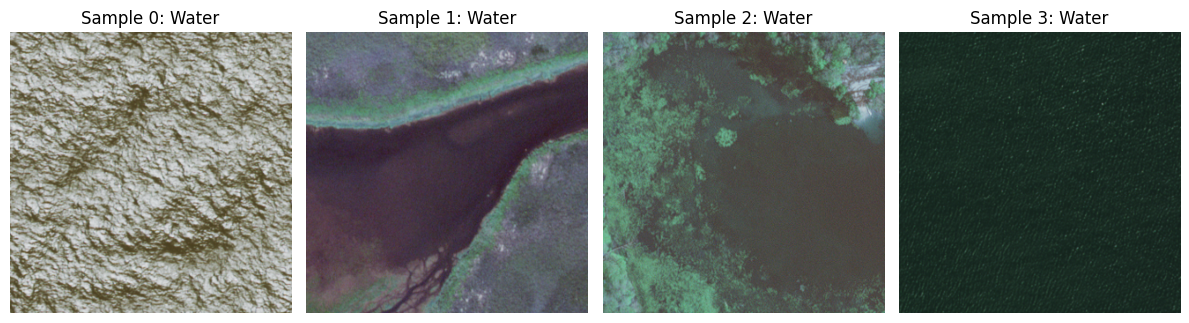

In [ ]:
train_dataset = FireRiskDataset(DB_DIR / 'train_reduced.csv', DB_DIR)
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

for i, ax in enumerate(axes):
    ax.axis('off')
    if i >= len(train_dataset):
        continue
    sample = train_dataset[i]
    print(i, sample['image'].shape, sample['label'])
    ax.set_title(f"Sample {i}: {CLASS_NAMES[sample['label']]}")
    ax.imshow(sample['image'])

fig.tight_layout()
plt.show()

**IMPORTANT:** `maxSize` optionally limits the number of images by selecting a reproducible random subset. Set `maxSize=0` to use the full split.

Small subsets are useful for checking code and exploring hyperparameters quickly. Conclusions obtained from a subset may differ from those obtained with the full training split. Use the full training split for your final model.


### Preprocessing and data augmentation

Augmentation creates random variations of training images and can *improve* generalisation and thus *reduce* potential overfitting. Apply random augmentation to **training** data; validation and test preprocessing should be deterministic.

We implement five callable transforms:

- `Rescale`: resize to a specified shape, or resize the shorter side while preserving aspect ratio.
- `RandomCrop`: select a random image patch, used during training.
- `CenterCrop`: take the central patch, used for validation and test.
- `ToTensor`: convert a NumPy image from `H x W x C` to a float32 PyTorch tensor in `C x H x W` order.
- `Normalize`: subtract the RGB channel means and divide by the channel standard deviations.

Callable classes store transform parameters in `__init__` and apply the operation in `__call__`:

```python
tsfm = Transform(parameters)
transformed_sample = tsfm(sample)
```

Crops must fit the input image. Resize first if you want to crop an image that is smaller than the requested crop.


In [ ]:
def _crop_size(output_size):

    if isinstance(output_size, numbers.Integral):
        output_size = (int(output_size), int(output_size))

    if (not isinstance(output_size, tuple) or len(output_size) != 2 or
        any(not isinstance(v, numbers.Integral) or v <= 0 for v in output_size)):
        raise ValueError('Size must be a positive integer or a pair of positive integers.')

    return tuple(int(v) for v in output_size)

class Rescale:
    """Resize to (height, width), or resize the shorter side preserving aspect ratio."""

    def __init__(self, output_size):
        self.output_size = (int(output_size) if isinstance(output_size, numbers.Integral)
                            else _crop_size(output_size))
        if isinstance(self.output_size, int) and self.output_size <= 0:
            raise ValueError('The output size must be positive.')

    def __call__(self, sample):
        image, label = sample['image'], sample['label']
        h, w = image.shape[:2]
        if isinstance(self.output_size, int):
            scale = self.output_size / min(h, w)
            new_h, new_w = round(h * scale), round(w * scale)
        else:
            new_h, new_w = self.output_size
        image = transform.resize(image, (new_h, new_w), anti_aliasing=True)

        return {'image': image.astype(np.float32), 'label': label}

class RandomCrop:
    """Choose uniformly among all valid crops, including the final row/column."""

    def __init__(self, output_size):
        self.output_size = _crop_size(output_size)

    def __call__(self, sample):

        image, label = sample['image'], sample['label']
        h, w = image.shape[:2]
        new_h, new_w = self.output_size

        if new_h > h or new_w > w:
            raise ValueError('Crop exceeds image dimensions; resize the image first.')
        top = np.random.randint(0, h - new_h + 1)
        left = np.random.randint(0, w - new_w + 1)

        return {'image': image[top:top + new_h, left:left + new_w], 'label': label}

class CenterCrop:
    """Take a deterministic central crop without silently changing its size."""

    def __init__(self, output_size):
        self.output_size = _crop_size(output_size)

    def __call__(self, sample):

        image, label = sample['image'], sample['label']
        h, w = image.shape[:2]
        new_h, new_w = self.output_size

        if new_h > h or new_w > w:
            raise ValueError('Crop exceeds image dimensions; resize the image first.')
        top, left = (h - new_h) // 2, (w - new_w) // 2

        return {'image': image[top:top + new_h, left:left + new_w], 'label': label}

class ToTensor:
    """Convert HWC images to contiguous float32 CHW tensors and labels to int64."""

    def __call__(self, sample):
        image = np.ascontiguousarray(sample['image'].transpose(2, 0, 1), dtype=np.float32)
        return {'image': torch.from_numpy(image),
                'label': torch.tensor(sample['label'], dtype=torch.long)}

class Normalize:
    """Apply per-channel normalisation without mutating the input tensor."""

    def __init__(self, mean, std):

        self.mean = np.asarray(mean, dtype=np.float32)
        self.std = np.asarray(std, dtype=np.float32)

        if (self.mean.ndim != 1 or self.std.shape != self.mean.shape or
            not np.isfinite(self.mean).all() or not np.isfinite(self.std).all() or
            not (self.std > 0).all()):
            raise ValueError('Mean/std must be matching finite vectors with positive std.')

    def __call__(self, sample):

        image = sample['image']

        if image.ndim != 3 or image.shape[0] != len(self.mean):
            raise ValueError('The CHW tensor and normalisation vectors must match.')

        mean = torch.as_tensor(self.mean, dtype=image.dtype, device=image.device)[:, None, None]
        std = torch.as_tensor(self.std, dtype=image.dtype, device=image.device)[:, None, None]
        return {'image': (image - mean) / std, 'label': sample['label']}

We can experiment with the different transformation methods for data augmentation

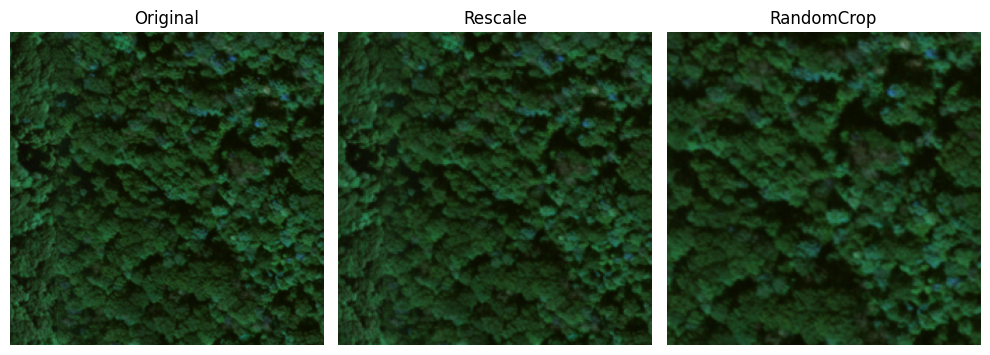

In [ ]:
# Modify the transform parameters to explore their effects.
sample = train_dataset[min(100, len(train_dataset) - 1)]

fig, axes = plt.subplots(1, 3, figsize=(10, 4))
axes[0].imshow(sample['image'])
axes[0].set_title('Original')

for ax, tsfrm in zip(axes[1:], [Rescale(224), RandomCrop(224)]):
    ax.imshow(tsfrm(sample)['image'])
    ax.set_title(type(tsfrm).__name__)
for ax in axes:
    ax.axis('off')

fig.tight_layout()

plt.show()

 The torchvision.transforms package

`torchvision.transforms` supplies many useful image transforms. Depending on the transform, inputs can be PIL images or PyTorch tensors. Our dataset initially returns NumPy images, so a wrapper may need to:

1. Convert the NumPy image to a PIL image.
2. Apply a torchvision transform.
3. Convert back to a NumPy image while preserving the label.

The `TVCenterCrop` class below demonstrates this pattern. This is an image-classification task: there is no segmentation mask to transform. When adapting this pattern to segmentation, image and mask geometry would need to remain aligned.


In [ ]:
# Adapts Pytorch's Center Crop to work on dictionary style dataset samples containing NP array images
class TVCenterCrop:
    """Wrap torchvision CenterCrop for a NumPy image/sample dictionary."""

    def __init__(self, size):
        self.size = _crop_size(size)
        self.crop = transforms.CenterCrop(self.size)

    def __call__(self, sample):

        image = sample['image']

        if any(crop > actual for crop, actual in zip(self.size, image.shape[:2])):
            raise ValueError('Crop exceeds image dimensions; resize the image first.')

        pil_image = Image.fromarray(util.img_as_ubyte(image))
        image = util.img_as_float32(np.asarray(self.crop(pil_image)))
        return {'image': image, 'label': sample['label']}

Apply the wrapper to inspect its output.


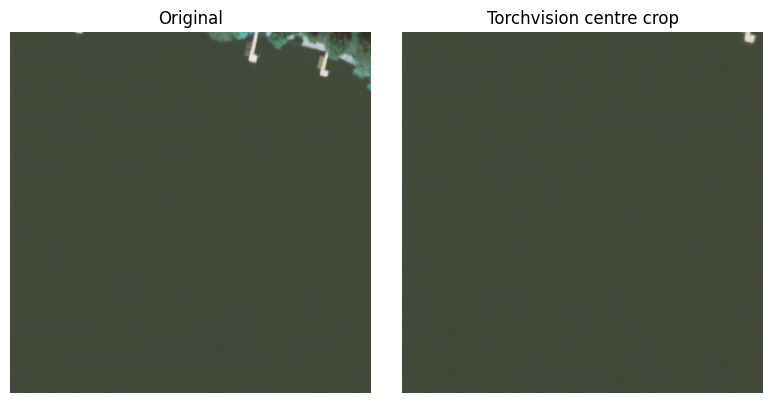

In [ ]:
sample = train_dataset[min(65, len(train_dataset) - 1)]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample['image'])
axes[0].set_title('Original')
axes[1].imshow(TVCenterCrop(256)(sample)['image'])
axes[1].set_title('Torchvision centre crop')

for ax in axes:
    ax.axis('off')

fig.tight_layout()

plt.show()

In [ ]:
# Other examples of transformations using scikit-image and torchvision.transforms would be the following

# Not a method, it just allows for declaring multiple operations
class Compose:
    """Applies a list of dictionary-based transforms in sequence."""
    def __init__(self, transforms_list):
        self.transforms = transforms_list

    def __call__(self, sample):
        for t in self.transforms:
            sample = t(sample)
        return sample

## EXAMPLE CASE:
# train_transform = Compose([
#     SkResize((300, 300)),
#     TVRandomHorizontalFlip(p=0.5),
#     TVRandomRotation(degrees=15),
#     TVColorJitter(brightness=0.1, contrast=0.1),
#     TVCenterCrop(256),
#     SkAddGaussianNoise(var=0.005)
# ])

# Torch vision transformations
class TVRandomHorizontalFlip:
    """Randomly flips the image horizontally with probability p."""
    def __init__(self, p=0.5):
        self.p = p
        self.flip = transforms.RandomHorizontalFlip(p=1.0)

    def __call__(self, sample):
        if random.random() < self.p:
            image = sample['image']
            pil_img = Image.fromarray(util.img_as_ubyte(image))
            image = util.img_as_float32(np.asarray(self.flip(pil_img)))
            return {'image': image, 'label': sample['label']}
        return sample


class TVRandomRotation:
    """Rotates the image by a random angle within [-degrees, +degrees]."""
    def __init__(self, degrees=15):
        self.rotate = transforms.RandomRotation(degrees=degrees)

    def __call__(self, sample):
        image = sample['image']
        pil_img = Image.fromarray(util.img_as_ubyte(image))
        image = util.img_as_float32(np.asarray(self.rotate(pil_img)))
        return {'image': image, 'label': sample['label']}


class TVColorJitter:
    """Randomly changes brightness, contrast, saturation, and hue."""
    def __init__(self, brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1):
        self.jitter = transforms.ColorJitter(
            brightness=brightness, 
            contrast=contrast, 
            saturation=saturation, 
            hue=hue
        )

    def __call__(self, sample):
        image = sample['image']
        pil_img = Image.fromarray(util.img_as_ubyte(image))
        image = util.img_as_float32(np.asarray(self.jitter(pil_img)))
        return {'image': image, 'label': sample['label']}


# Scikit-Image Transformations
class SkResize:
    """Resizes the image to a target output size (height, width)."""
    def __init__(self, output_size):
        if isinstance(output_size, int):
            self.output_size = (output_size, output_size)
        else:
            self.output_size = output_size

    def __call__(self, sample):
        image = sample['image']
        resized = transform.resize(
            image, 
            self.output_size, 
            anti_aliasing=True, 
            mode='reflect'
        )
        return {'image': resized.astype(np.float32), 'label': sample['label']}


class SkAddGaussianNoise:
    """Adds zero-mean Gaussian noise for robustness against sensor noise."""
    def __init__(self, var=0.01):
        self.var = var

    def __call__(self, sample):
        image = sample['image']
        noisy = util.random_noise(image, mode='gaussian', var=self.var)
        return {'image': noisy.astype(np.float32), 'label': sample['label']}


class SkAdjustGamma:
    """Performs Gamma Correction for illumination augmentation."""
    def __init__(self, gamma_range=(0.7, 1.5)):
        self.gamma_range = gamma_range

    def __call__(self, sample):
        image = sample['image']
        gamma = random.uniform(*self.gamma_range)
        adjusted = exposure.adjust_gamma(image, gamma=gamma)
        return {'image': adjusted.astype(np.float32), 'label': sample['label']}


# Dihedral augmentation as satellite imagery is invariant to orientation
class RandomDihedral:
    def __call__(self, sample):
        image = sample['image']

        if isinstance(image, np.ndarray):
            pil_img = Image.fromarray(util.img_as_ubyte(image))
        else:
            pil_img = image

        # Orthogonal rotation
        angle = random.choice([0, 90, 180, 270])
        if angle > 0:
            pil_img = TF.rotate(pil_img, angle)

        # Horizontal flip
        if random.random() < 0.5:
            pil_img = TF.hflip(pil_img)

        if isinstance(image, np.ndarray):
            image = util.img_as_float32(np.asarray(pil_img))
        else:
            image = pil_img

        return {'image': image, 'label': sample['label']}


class TVRandomResizedCrop:
    """Randomly crops and resizes the image to a target output size."""
    def __init__(self, size, scale=(0.7, 1.0), ratio=(0.9, 1.1)):
        self.crop = transforms.RandomResizedCrop(
            size=size,
            scale=scale,
            ratio=ratio
        )

    def __call__(self, sample):
        image = sample['image']
        pil_img = Image.fromarray(util.img_as_ubyte(image))
        cropped = self.crop(pil_img)
        image = util.img_as_float32(np.asarray(cropped))
        return {'image': image, 'label': sample['label']}

 Composing transforms

The next example applies colour jitter and horizontal and vertical flips with probability 0.5, followed by tensor conversion and normalisation. Random transforms can generate many variants of an image, but they do **not** create independent observations beyond the original dataset.

Each time a training image is read, a new random transformation can be sampled. Transform parameters control the range of variation. Undo normalisation before displaying the result, so the plot shows meaningful RGB colours.


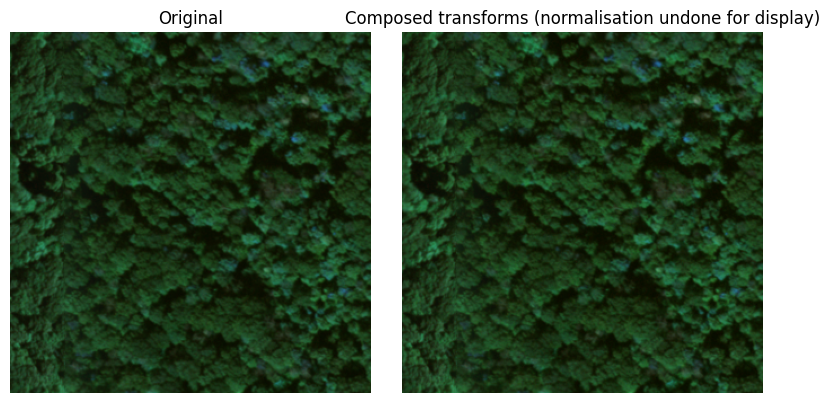

In [ ]:
# We can modify the order of this values to see how the values change
composed = transforms.Compose([
    transforms.ColorJitter(brightness=0.05, contrast=0.05, saturation=0.05, hue=0.01),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(PIXEL_MEAN, PIXEL_STD),
])

def image_for_display(tensor):
    """Undo RGB normalisation and convert CHW to displayable HWC pixels."""

    image = tensor.detach().cpu()

    mean = torch.tensor(PIXEL_MEAN, dtype=image.dtype)[:, None, None]
    std = torch.tensor(PIXEL_STD, dtype=image.dtype)[:, None, None]

    return (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

sample = train_dataset[min(100, len(train_dataset) - 1)]

pil_sample = Image.fromarray(util.img_as_ubyte(sample['image']))
transformed_sample = composed(pil_sample)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample['image'])
axes[0].set_title('Original')
axes[1].imshow(image_for_display(transformed_sample))
axes[1].set_title('Composed transforms (normalisation undone for display)')

for ax in axes:
    ax.axis('off')

fig.tight_layout()

plt.show()

One important consideration would be to consider which augmentation methods represent reasonable variation in satellite imagery without changing its class. Chosing the best method that will improve generalization

### Iterating over the dataset

Combine image loading and transforms to create the training, validation and test datasets.

For each training sample, the dataset reads the image, applies the transform composition and returns the resulting tensor and label. Random cropping provides augmentation. Validation and test use a deterministic central crop.


In [ ]:
train_dataset = FireRiskDataset(
    DB_DIR / 'train_reduced.csv', DB_DIR, maxSize=MAX_TRAIN_SAMPLES,
    transform=transforms.Compose([
        RandomCrop(224), ToTensor(), Normalize(PIXEL_MEAN, PIXEL_STD),
    ]))

val_dataset = FireRiskDataset(
    DB_DIR / 'val_reduced.csv', DB_DIR,
    transform=transforms.Compose([
        CenterCrop(224), ToTensor(), Normalize(PIXEL_MEAN, PIXEL_STD),
    ]))

test_dataset = FireRiskDataset(
    DB_DIR / 'test_reduced.csv', DB_DIR,
    transform=transforms.Compose([
        CenterCrop(224), ToTensor(), Normalize(PIXEL_MEAN, PIXEL_STD),
    ]))

for i in range(min(4, len(train_dataset))):
    sample = train_dataset[i]
    print(i, sample['image'].shape, int(sample['label']))

print(f'Training subset size: {len(train_dataset)}')

0 torch.Size([3, 224, 224]) 0
1 torch.Size([3, 224, 224]) 0
2 torch.Size([3, 224, 224]) 0
3 torch.Size([3, 224, 224]) 0
Training subset size: 3516


Finally, create DataLoaders to group samples into batches and shuffle training examples.

`torch.utils.data.DataLoader` is an iterable that can also load data using worker processes. `num_workers=0` is the portable notebook default here: notebook-defined dataset classes can cause multiprocessing problems on platforms that use process spawning. Increase the worker count only after verifying that your environment supports it.

The default `collate_fn` stacks the tensors in our sample dictionaries. Keep validation and test loaders unshuffled; submission rows must follow the test CSV order.


0 torch.Size([64, 3, 224, 224]) tensor([2, 2, 3, 1, 6, 1, 1, 1, 3, 5, 2, 6, 2, 1, 1, 3, 3, 2, 2, 6, 4, 2, 2, 3,
        2, 1, 6, 6, 1, 1, 1, 5, 3, 4, 1, 1, 6, 5, 3, 4, 3, 6, 3, 5, 3, 1, 1, 6,
        1, 1, 6, 4, 2, 6, 1, 5, 6, 6, 6, 1, 0, 1, 1, 2])


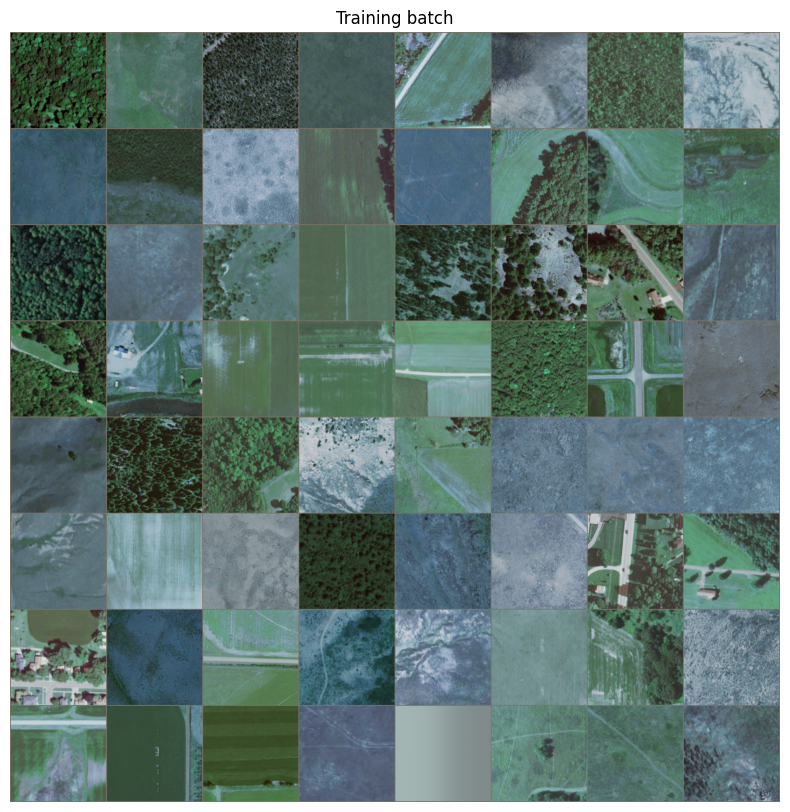

1 torch.Size([64, 3, 224, 224]) tensor([2, 1, 6, 6, 1, 0, 2, 3, 4, 1, 6, 6, 4, 6, 6, 1, 2, 6, 2, 3, 4, 2, 2, 2,
        1, 1, 1, 0, 2, 1, 3, 2, 2, 6, 1, 1, 2, 2, 2, 0, 2, 1, 5, 1, 0, 1, 1, 2,
        4, 1, 4, 1, 4, 5, 1, 4, 6, 1, 1, 1, 6, 3, 3, 1])


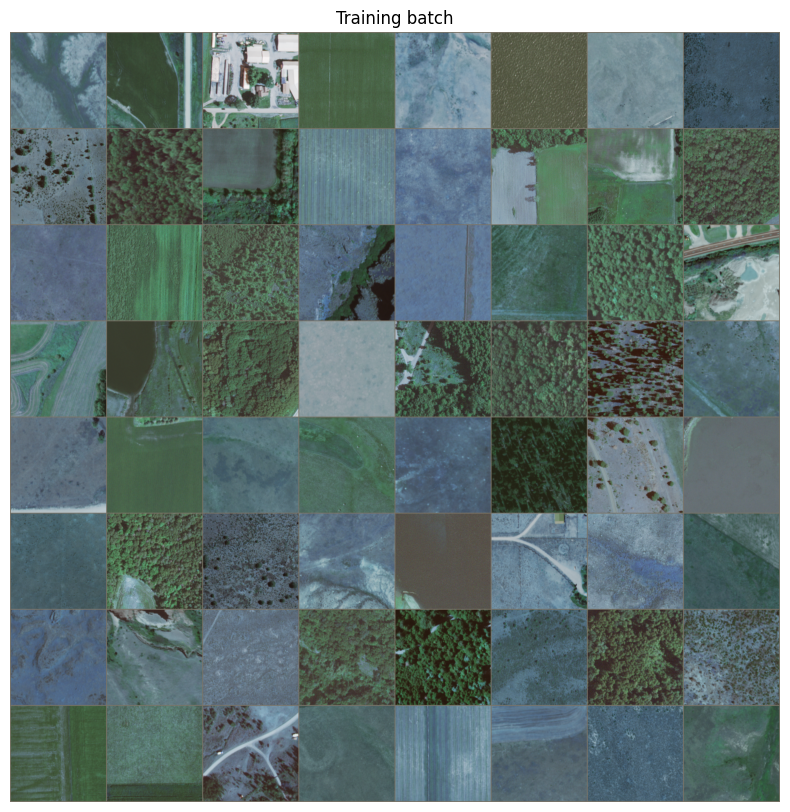

2 torch.Size([64, 3, 224, 224]) tensor([6, 2, 1, 6, 1, 3, 3, 2, 4, 4, 5, 6, 1, 1, 2, 2, 3, 0, 1, 6, 1, 1, 6, 6,
        1, 6, 0, 6, 1, 1, 1, 6, 1, 6, 5, 6, 1, 5, 1, 6, 1, 6, 3, 1, 1, 6, 2, 1,
        6, 1, 3, 6, 1, 3, 1, 2, 3, 1, 1, 1, 2, 3, 1, 1])


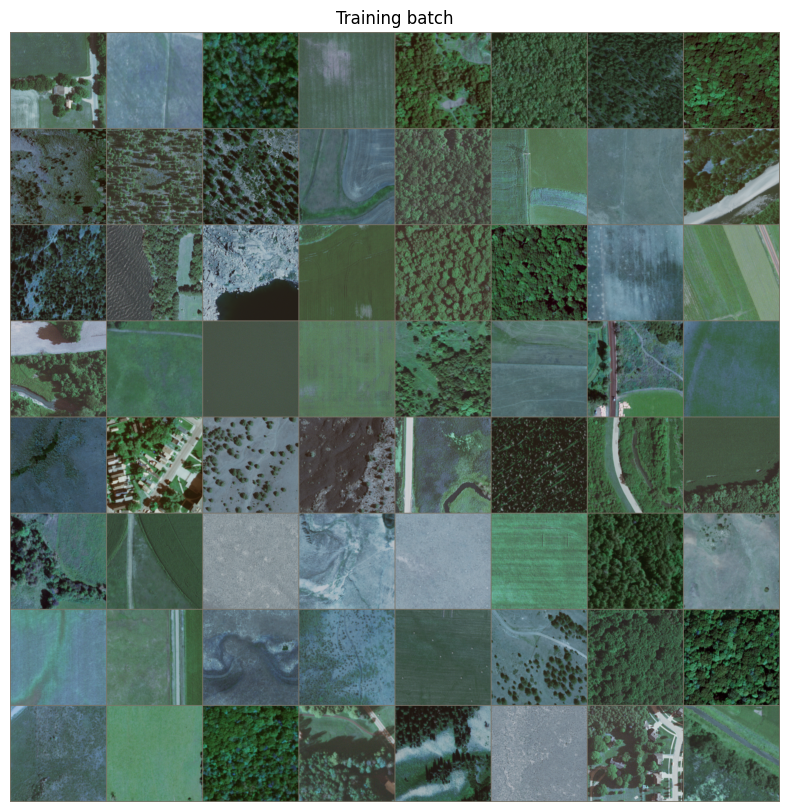

3 torch.Size([64, 3, 224, 224]) tensor([1, 1, 1, 0, 2, 4, 2, 6, 6, 2, 3, 2, 1, 3, 6, 2, 3, 1, 1, 1, 1, 1, 4, 1,
        6, 6, 6, 1, 6, 2, 2, 2, 6, 1, 1, 3, 6, 1, 1, 3, 6, 6, 1, 1, 6, 1, 3, 2,
        4, 2, 6, 1, 6, 4, 3, 1, 1, 1, 6, 1, 1, 2, 4, 2])


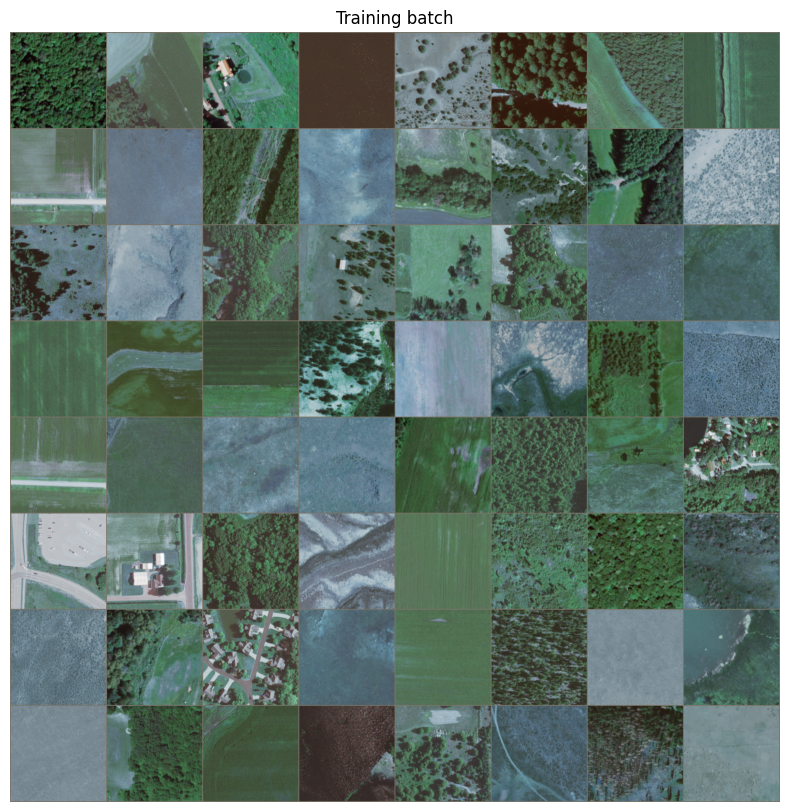

In [ ]:
def seed_worker(worker_id):
    # PyTorch assigns a worker seed; also seed NumPy and Python random.
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_generator = torch.Generator().manual_seed(SEED)
train_dataloader = DataLoader(
    train_dataset, batch_size=64, shuffle=True, num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker, generator=train_generator)
val_dataloader = DataLoader(
    val_dataset, batch_size=128, shuffle=False, num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker)
test_dataloader = DataLoader(
    test_dataset, batch_size=128, shuffle=False, num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker)

def show_batch(sample_batched):
    grid = utils.make_grid(sample_batched['image'])
    plt.imshow(image_for_display(grid))
    plt.title('Training batch')
    plt.axis('off')

for i_batch, sample_batched in enumerate(train_dataloader):
    print(i_batch, sample_batched['image'].shape, sample_batched['label'])
    plt.figure(figsize=(10, 10))
    show_batch(sample_batched)
    plt.show()
    if i_batch == 3:
        break

## Building a custom fire-risk network

In this second part of the notebook we will be focused on building a CNN from scratch. Its architecture must match the input image size; this reference pipeline uses 224 x 224 crops.

The next cell defines `CustomNet`, with `__init__` to create layers and `forward` to connect them. The network must map a batch of shape `N x 3 x 224 x 224` to seven logits per image, shape `N x 7`. Pass raw logits to cross-entropy; apply softmax *only* when obtaining probabilities for reporting or submission.

In [ ]:
class CustomNet(nn.Module):
    """Implement a CNN mapping N x 3 x 224 x 224 to N x 7 logits."""

    def __init__(self):
        super().__init__()
        # Define conv1, conv2, conv3, pool, fc1 and fc2 here.
        # Suggested channel progression: 3 -> 6 -> 16 -> 32.
        # Three 5x5 convolutions and 2x2 pools leave 24x24 spatial features.
        # Each convolution must have a distinct name: do not overwrite conv2.
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5)
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5)
        self.conv3 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5)

        # Max pooling
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Fully connected layers
        self.fc1 = nn.Linear(32 * 24 * 24, 120)
        self.fc2 = nn.Linear(120, 7)

    def forward(self, x):
        # Connect the layers you define in __init__ using this reference graph.
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [ ]:
# Making sure the network accepts input tensors of shape (N,3,224,224)
seed_everything()

customNet = CustomNet().to(device)

data = next(iter(train_dataloader))
inputs = data['image'].to(device, dtype=torch.float32)

print(f'Input batch shape: {tuple(inputs.shape)}')

with torch.no_grad():
    outputs = customNet(inputs)
if outputs.shape != (inputs.shape[0], NUM_CLASSES):
    raise ValueError('CustomNet must produce one seven-score vector per image.')

print(f'Output batch shape: {tuple(outputs.shape)}')

Input batch shape: (64, 3, 224, 224)
Output batch shape: (64, 7)


## Training the Network

We now define the evaluation metric, loss, optimiser and learning-rate schedule.

### Evaluation metric: macro F1

For a class, precision is the fraction of predicted positives that are correct, and recall is the fraction of actual positives correctly identified:

$$\operatorname{precision}=\frac{TP}{TP+FP},\qquad
\operatorname{recall}=\frac{TP}{TP+FN}.$$

F1 is their harmonic mean:

$$F_1=\frac{2\,\operatorname{precision}\,\operatorname{recall}}
{\operatorname{precision}+\operatorname{recall}}
=\frac{2TP}{2TP+FP+FN}.$$

For seven classes, macro F1 gives each class equal weight:

$$\operatorname{MacroF1}=\frac{1}{7}\sum_{c=0}^{6}F_{1,c}.$$

We explicitly include all seven labels. Undefined per-class scores are assigned zero, which makes evaluation well-defined when a small split omits a class. Macro F1 highlights class-level performance under imbalance, but it should still be inspected alongside per-class results.

### Confusion matrix

Rows represent **true classes** and columns represent **predicted classes**. A row-normalised matrix divides each row by the number of true examples in that class. The display uses percentages and the fixed numeric class order. A class with no true examples has a zero row, rather than an undefined division.

Background references: [F-score](https://en.wikipedia.org/wiki/F-score#Macro_F1) and [confusion matrix](https://en.wikipedia.org/wiki/Confusion_matrix).

### Loss, optimiser and learning-rate schedule

We configure:

- Cross-entropy on raw logits. This variant uses the ordinary unweighted mean.
- Stochastic gradient descent with momentum 0.9.
- `StepLR`, which multiplies the learning rate by 0.1 every seven training epochs.

Choose hyperparameters using validation results, rather than assuming that a particular learning rate or weighting scheme is universally better.



In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer_ft = optim.SGD(customNet.parameters(), lr=CUSTOM_LR, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

### Training function

The function has three nested loops:

- **Epochs:** repeat training and validation for the configured budget.
- **Phases:** update parameters in training mode, then evaluate in validation mode without gradients.
- **Batches:** compute logits and loss; run backpropagation and optimiser updates only during training.

Select and restore the checkpoint with the highest validation macro F1. This is **best-checkpoint selection**, not early stopping: all requested epochs are run. Weighted epoch losses are aggregated using their weight denominators so the reported loss is not distorted by batch composition. Validation macro F1 remains unweighted.


In [ ]:
def train_model(model, criterion, optimizer, scheduler,
                num_epochs=25, plot_confusion_matrix=True):
    """Run fixed-budget training and restore the best validation-macro-F1 model."""

    if not isinstance(num_epochs, numbers.Integral) or num_epochs < 1:
        raise ValueError('num_epochs must be a positive integer.')
    if not isinstance(criterion, nn.CrossEntropyLoss) or criterion.reduction != 'mean':
        raise ValueError('Use CrossEntropyLoss with reduction="mean".')
    if any(len(dataloaders[phase].dataset) == 0 for phase in ('train', 'val')):
        raise ValueError('Training and validation datasets must be nonempty.')

    seed_everything()

    if dataloaders['train'].generator is not None:
        dataloaders['train'].generator.manual_seed(SEED)

    criterion = criterion.to(device)

    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_f1 = -float('inf')
    best_predictions = best_labels = None
    labels_order = np.arange(NUM_CLASSES)

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        for phase in ('train', 'val'):
            model.train(phase == 'train')
            running_loss = 0.0
            loss_denominator = 0.0
            phase_predictions, phase_labels = [], []

            for sample in dataloaders[phase]:
                inputs = sample['image'].to(device, dtype=torch.float32)
                labels = sample['label'].to(device, dtype=torch.long)

                if phase == 'train':
                    optimizer.zero_grad(set_to_none=True)
                with torch.set_grad_enabled(phase == 'train'):
                    logits = model(inputs)
                    if logits.shape != (labels.numel(), NUM_CLASSES):
                        raise ValueError('The network must return N x 7 logits.')
                    loss = criterion(logits, labels)
                    if not torch.isfinite(loss):
                        raise ValueError('Non-finite loss; check inputs and optimiser settings.')
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                denominator = (labels.numel() if criterion.weight is None else
                               criterion.weight[labels].sum().item())
                running_loss += loss.item() * denominator
                loss_denominator += denominator
                phase_predictions.append(logits.detach().argmax(dim=1).cpu().numpy())
                phase_labels.append(labels.detach().cpu().numpy())

            if phase == 'train' and scheduler is not None:
                scheduler.step()
            predictions = np.concatenate(phase_predictions)
            true_labels = np.concatenate(phase_labels)
            epoch_loss = running_loss / loss_denominator
            epoch_f1 = f1_score(true_labels, predictions, labels=labels_order,
                                average='macro', zero_division=0)
            print(f'{phase} Loss: {epoch_loss:.4f} Macro F1-score: {epoch_f1:.4f}')
            if phase == 'val' and epoch_f1 > best_f1:
                best_f1 = epoch_f1
                best_model_wts = copy.deepcopy(model.state_dict())
                best_predictions = predictions.copy()
                best_labels = true_labels.copy()
        print()

    model.load_state_dict(best_model_wts)
    model.eval()

    elapsed = time.time() - since
    print(f'Training complete in {int(elapsed // 60)}m {int(elapsed % 60)}s')
    print(f'Best validation macro F1-score: {best_f1:.6f}')

    if plot_confusion_matrix:
        cm = confusion_matrix(best_labels, best_predictions, labels=labels_order,
                              normalize='true')
        display = ConfusionMatrixDisplay(100 * cm, display_labels=CLASS_NAMES)
        display.plot(xticks_rotation='vertical', values_format='.1f')
        plt.title('Row-normalised confusion matrix (%)')
        plt.tight_layout()
        plt.show()

    return model

In [ ]:
image_datasets = {'train': train_dataset, 'val': val_dataset}

dataloaders = {'train': train_dataloader, 'val': val_dataloader}

dataset_sizes = {phase: len(dataset) for phase, dataset in image_datasets.items()}
class_names = CLASS_NAMES.copy()

Epoch 0/4
----------
train Loss: 1.7390 Macro F1-score: 0.1092
val Loss: 1.6007 Macro F1-score: 0.1299

Epoch 1/4
----------
train Loss: 1.5498 Macro F1-score: 0.1672
val Loss: 1.5186 Macro F1-score: 0.2033

Epoch 2/4
----------
train Loss: 1.5076 Macro F1-score: 0.1777
val Loss: 1.4980 Macro F1-score: 0.1788

Epoch 3/4
----------
train Loss: 1.4806 Macro F1-score: 0.2061
val Loss: 1.4896 Macro F1-score: 0.2272

Epoch 4/4
----------
train Loss: 1.4679 Macro F1-score: 0.2083
val Loss: 1.4669 Macro F1-score: 0.1997

Training complete in 3m 41s
Best validation macro F1-score: 0.227167


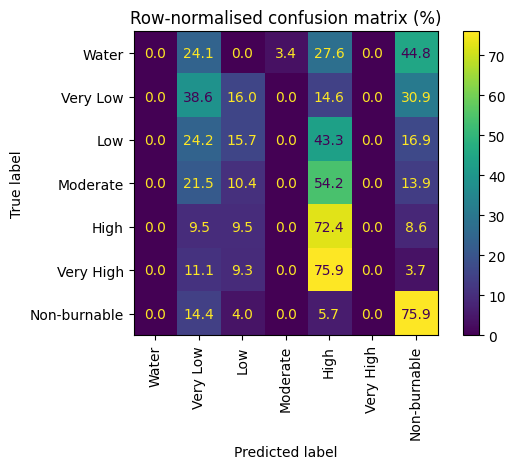

In [24]:
# Initializing actual training
customNet = train_model(customNet, criterion, optimizer_ft, exp_lr_scheduler,
                        num_epochs=CUSTOM_EPOCHS)

It predicts the main class due to the big imbalance.

This is just a base benchmark, for evaluating how the model works, how data is loaded and how to apply data augmentation.

Of course, this results are far from good. We will have to implement better architectures, optimizers and learning rates, more epochs and potentially checkpoints for long training runs

## Transfer Learning

Fine-tuning a pretrained network.

Instead of training every weight from scratch, adapt a CNN pretrained on a different task. This can be useful when the available training set is small relative to the model size.

We use torchvision's AlexNet with ImageNet weights. ImageNet has 1,000 output classes; this task has seven. Replace the final classifier layer with a newly initialised seven-output layer, then fine-tune the network.

The `weights` API replaces the deprecated `pretrained=True` argument. The first load may download weights. See the [official AlexNet documentation](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.alexnet.html).


In [25]:
# This category uses ImageNet pretraining; do not disable it for a final submission.
seed_everything()

alexnet_weights = models.AlexNet_Weights.IMAGENET1K_V1
ftNet = models.alexnet(weights=alexnet_weights)

num_features = ftNet.classifier[6].in_features
ftNet.classifier[6] = nn.Linear(num_features, NUM_CLASSES)
ftNet = ftNet.to(device)

print(ftNet)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to C:\Users\javie/.cache\torch\hub\checkpoints\alexnet-owt-7be5be79.pth
100%|██████████| 233M/233M [00:19<00:00, 12.5MB/s] 


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

In [26]:
# Creating a new optimizer for this dataset
optimizer_ft = optim.SGD(ftNet.parameters(), lr=FT_LR, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

Epoch 0/4
----------
train Loss: 1.4418 Macro F1-score: 0.2561
val Loss: 1.2791 Macro F1-score: 0.3771

Epoch 1/4
----------
train Loss: 1.2681 Macro F1-score: 0.3614
val Loss: 1.2064 Macro F1-score: 0.4019

Epoch 2/4
----------
train Loss: 1.1899 Macro F1-score: 0.4070
val Loss: 1.1782 Macro F1-score: 0.4041

Epoch 3/4
----------
train Loss: 1.1542 Macro F1-score: 0.4382
val Loss: 1.2027 Macro F1-score: 0.4227

Epoch 4/4
----------
train Loss: 1.1229 Macro F1-score: 0.4533
val Loss: 1.1533 Macro F1-score: 0.4352

Training complete in 3m 10s
Best validation macro F1-score: 0.435197


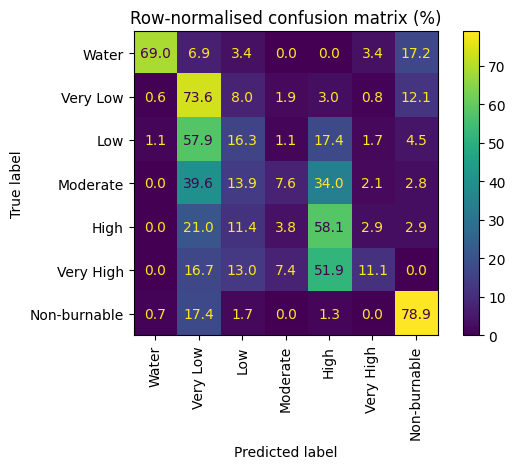

In [27]:
# Training 
ftNet = train_model(ftNet, criterion, optimizer_ft, exp_lr_scheduler,
                    num_epochs=FT_EPOCHS)

Current implements ImageNet-pretrained on AlexNet. Other pretrained architectures ensuring they produce seven outputs could produce better results.

## Final models

The baselines above only validate the pipeline: the small CNN collapses to the majority class and AlexNet reaches a modest macro F1. The cells below implement the two models submitted to CodaBench:

- **CUSTOM:** a residual CNN designed and trained from scratch.
- **FINE-TUNING:** a DINOv3 ViT-L backbone pretrained on satellite imagery, adapted with a linear classification head.

Both share the improved data pipeline, class-imbalance handling and a training loop with early stopping.

### Class imbalance

Plain inverse-frequency weights gave far more gradient weight to *Water*, which is an easy class, and hurt the harder risk levels. The softened version uses `(1 / freq) ** 0.5`, rescaled to a mean of 1, which reduces this gap.

In [28]:
def compute_class_weights(train_dataset):
    """Computes Inverse Class Frequency weights as a PyTorch Tensor."""
    train_df = train_dataset.dataset
    class_counts = train_df['label'].value_counts().sort_index().values
    total_samples = len(train_df)

    weights = total_samples / (NUM_CLASSES * class_counts.astype(np.float32))
    print(f"Class distribution: {class_counts}")
    print(f"Class loss weights: {weights}")

    return torch.tensor(weights, dtype=torch.float32).to(device)

# Better results as above, above was giving much more gradient weights to water which showed to be less hard to distinguish thus affecting the model
# This forces weights to average a value of 1 and reduces this penalty gap
def compute_softened_class_weights(dataset, num_classes=NUM_CLASSES):
    labels = dataset.dataset['label'].values
    counts = torch.bincount(torch.tensor(labels, dtype=torch.long), minlength=num_classes).float()
    freqs = counts / counts.sum()
    raw_weights = (1.0 / freqs) ** 0.5
    softened_weights = raw_weights / raw_weights.mean()
    return softened_weights.to(device)

### Data pipeline

Training uses random resized crops, the 8 dihedral orientations (aerial images have no canonical "up") and mild colour jitter. Validation and test use a deterministic centre crop.

In [29]:
def get_dataloaders(batch_size=32, img_size=320):
    train_transform = Compose([
        TVRandomResizedCrop(img_size, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
        RandomDihedral(), # All 8 valid orientations
        TVColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
        ToTensor(),
        Normalize(PIXEL_MEAN, PIXEL_STD),
    ])

    eval_transform = Compose([
        CenterCrop(img_size),
        ToTensor(),
        Normalize(PIXEL_MEAN, PIXEL_STD),
    ])

    train_ds = FireRiskDataset(DB_DIR / 'train_reduced.csv', DB_DIR, transform=train_transform)
    val_ds = FireRiskDataset(DB_DIR / 'val_reduced.csv', DB_DIR, transform=eval_transform)
    test_ds = FireRiskDataset(DB_DIR / 'test_reduced.csv', DB_DIR, transform=eval_transform)

    train_loader = DataLoader(
    train_ds,
    batch_size=batch_size,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=NUM_WORKERS > 0
    )
    val_loader = DataLoader(
    val_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=NUM_WORKERS > 0
    )
    test_loader = DataLoader(
    test_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
    )

    return train_loader, val_loader, test_loader, train_ds

### Training with early stopping

Same loop as `train_model`, but it takes the loaders as arguments, supports `ReduceLROnPlateau`, and stops after `patience` epochs without a validation macro-F1 improvement. The best-validation checkpoint is restored at the end.

In [34]:
# Implements the above function, including the ReduceLRONplateau and early stopping
def train_model_es(model, criterion, optimizer, scheduler, train_loader, val_loader,
                num_epochs=25, patience=5, plot_confusion_matrix=True):
    """Run fixed-budget or early-stopped training and restore the best validation-macro-F1 model."""

    dataloaders = {'train': train_loader, 'val': val_loader}

    if not isinstance(num_epochs, numbers.Integral) or num_epochs < 1:
        raise ValueError('num_epochs must be a positive integer.')
    if not isinstance(criterion, nn.CrossEntropyLoss) or criterion.reduction != 'mean':
        raise ValueError('Use CrossEntropyLoss with reduction="mean".')
    if any(len(dataloaders[phase].dataset) == 0 for phase in ('train', 'val')):
        raise ValueError('Training and validation datasets must be nonempty.')

    seed_everything()

    if dataloaders['train'].generator is not None:
        dataloaders['train'].generator.manual_seed(SEED)

    criterion = criterion.to(device)

    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_f1 = -float('inf')
    best_predictions = best_labels = None
    labels_order = np.arange(NUM_CLASSES)

    epochs_no_improve = 0
    history = {'epoch': [], 'lr': [], 'train_loss': [], 'train_f1': [], 'val_loss': [], 'val_f1': []}

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        val_loss_epoch = None
        val_f1_epoch = None

        for phase in ('train', 'val'):
            model.train(phase == 'train')
            running_loss = 0.0
            loss_denominator = 0.0
            phase_predictions, phase_labels = [], []

            for sample in dataloaders[phase]:
                inputs = sample['image'].to(device, dtype=torch.float32)
                labels = sample['label'].to(device, dtype=torch.long)

                if phase == 'train':
                    optimizer.zero_grad(set_to_none=True)
                with torch.set_grad_enabled(phase == 'train'):
                    logits = model(inputs)
                    if logits.shape != (labels.numel(), NUM_CLASSES):
                        raise ValueError(f'The network must return N x {NUM_CLASSES} logits.')
                    loss = criterion(logits, labels)
                    if not torch.isfinite(loss):
                        raise ValueError('Non-finite loss; check inputs and optimiser settings.')
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                denominator = (labels.numel() if criterion.weight is None else
                               criterion.weight[labels].sum().item())
                running_loss += loss.item() * denominator
                loss_denominator += denominator
                phase_predictions.append(logits.detach().argmax(dim=1).cpu().numpy())
                phase_labels.append(labels.detach().cpu().numpy())

            predictions = np.concatenate(phase_predictions)
            true_labels = np.concatenate(phase_labels)
            epoch_loss = running_loss / loss_denominator
            epoch_f1 = f1_score(true_labels, predictions, labels=labels_order,
                                average='macro', zero_division=0)

            print(f'{phase} Loss: {epoch_loss:.4f} Macro F1-score: {epoch_f1:.4f}')
            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_f1'].append(epoch_f1)

            if phase == 'val':
                val_loss_epoch = epoch_loss
                val_f1_epoch = epoch_f1

                if epoch_f1 > best_f1:
                    best_f1 = epoch_f1
                    best_model_wts = copy.deepcopy(model.state_dict())
                    best_predictions = predictions.copy()
                    best_labels = true_labels.copy()
                    epochs_no_improve = 0
                else:
                    epochs_no_improve += 1

        history['epoch'].append(epoch)
        history['lr'].append(optimizer.param_groups[0]['lr'])

        # Step Learning Rate Scheduler
        if scheduler is not None:
            if isinstance(scheduler, lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss_epoch)
            else:
                scheduler.step()

        print()

        # Early Stopping Check
        if epochs_no_improve >= patience:
            print(f'Early stopping triggered after {patience} epochs without validation macro-F1 improvement.')
            break

    model.load_state_dict(best_model_wts)
    model.eval()
    model.history = history  # Per-epoch curves, see plot_history

    elapsed = time.time() - since
    print(f'Training complete in {int(elapsed // 60)}m {int(elapsed % 60)}s')
    print(f'Best validation macro F1-score: {best_f1:.6f}')

    if plot_confusion_matrix and best_labels is not None:
        cm = confusion_matrix(best_labels, best_predictions, labels=labels_order, normalize='true')
        display = ConfusionMatrixDisplay(100 * cm, display_labels=CLASS_NAMES)
        display.plot(xticks_rotation='vertical', values_format='.1f')
        plt.title('Row-normalised confusion matrix (%)')
        plt.tight_layout()
        plt.show()

    return model

In [35]:
def plot_history(history, name):
    """Plot loss, macro F1 and learning rate per epoch, and save the history as CSV."""
    df = pd.DataFrame(history)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    df.to_csv(OUTPUT_DIR / f'history_{name}.csv', index=False)
    best = df.loc[df['val_f1'].idxmax()]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, metric, label in zip(axes[:2], ('loss', 'f1'), ('Weighted cross-entropy', 'Macro F1')):
        ax.plot(df['epoch'], df[f'train_{metric}'], label='Train')
        ax.plot(df['epoch'], df[f'val_{metric}'], label='Validation')
        ax.axvline(best['epoch'], color='grey', linestyle='--', label=f"Best epoch ({int(best['epoch'])})")
        ax.set_xlabel('Epoch')
        ax.set_ylabel(label)
        ax.legend()
    axes[2].plot(df['epoch'], df['lr'])
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Learning rate')
    fig.suptitle(f"{name}: best validation macro F1 {best['val_f1']:.4f}")
    plt.tight_layout()
    plt.show()
    return df

### CUSTOM: residual CNN trained from scratch

A ResNet-18-style network built from standard PyTorch layers:

- Stride-2 3x3 stem with BatchNorm and SiLU.
- Four stages of widths 32/64/128/256, each with two residual blocks. Each stage after the first halves the resolution.
- Global average and global max pooling, concatenated, so the head sees both the overall texture and the strongest local evidence.
- Dropout 0.3 and a linear layer giving 7 logits.

Training setup:

- Inputs are 308x308 crops.
- Loss: class-weighted cross-entropy with label smoothing 0.1, since FireRisk labels are noisy.
- Optimiser: AdamW (lr 2e-3, weight decay 1e-2) with cosine annealing.
- Early stopping on validation macro F1.

In [36]:
class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, kernel_size=3, stride=stride, padding=1, bias=False)
        self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, kernel_size=3, stride=1, padding=1, bias=False)
        self.b2 = nn.BatchNorm2d(cout)

        self.skip = nn.Identity() if (cin == cout and stride == 1) else nn.Sequential(
            nn.Conv2d(cin, cout, kernel_size=1, stride=stride, bias=False),
            nn.BatchNorm2d(cout)
        )
        self.act = nn.SiLU(inplace=True)

    def forward(self, x):
        y = self.act(self.b1(self.c1(x)))
        y = self.b2(self.c2(y))
        return self.act(y + self.skip(x))

# Residual CustomNet (named differently from the baseline CustomNet above)
class CustomResNet(nn.Module):
    """Implement a residual CNN mapping N x 3 x H x W to N x 7 logits."""

    def __init__(self, num_classes = NUM_CLASSES,widths=(32, 64, 128, 256)):
        super().__init__()
        # Initial convolution
        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]),
            nn.SiLU(inplace=True)
        )

        #4 residual layers
        layers = []
        cin = widths[0]
        for i, cout in enumerate(widths):
            stride = 1 if i == 0 else 2
            layers.append(ResBlock(cin, cout, stride=stride))
            layers.append(ResBlock(cout, cout, stride=1))
            cin = cout

        self.stages = nn.Sequential(*layers)
        self.drop = nn.Dropout(0.3)

        # Lienar PRojection
        self.fc = nn.Linear(2 * widths[-1], num_classes)

    def forward(self, x):
        x = self.stages(self.stem(x))
        # Both average and max pooling
        avg_pool = x.mean(dim=(2, 3))
        max_pool = x.amax(dim=(2, 3))
        pooled = torch.cat([avg_pool, max_pool], dim=1)
        return self.fc(self.drop(pooled))

In [37]:
seed_everything()

# Loading data
train_loader_custom, val_loader_custom, test_loader_custom, train_dataset_custom = get_dataloaders(batch_size=128, img_size=308)
class_weights = compute_softened_class_weights(train_dataset_custom)

# Initializing the model
model_custom = CustomResNet().to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer_custom = optim.AdamW(model_custom.parameters(), lr=2e-3, weight_decay=1e-2)
scheduler_custom = lr_scheduler.CosineAnnealingLR(optimizer_custom, T_max=80, eta_min=1e-5)

trained_custom = train_model_es(
model=model_custom,
criterion=criterion,
optimizer=optimizer_custom,
scheduler=scheduler_custom,
train_loader=train_loader_custom,
val_loader=val_loader_custom,
num_epochs=100,
patience=8,
plot_confusion_matrix=True
)

RuntimeError: CUDA error: out of memory
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [ ]:
history_custom = plot_history(trained_custom.history, 'custom')

### FINE-TUNING: DINOv3 ViT-L/16 pretrained on SAT-493M

- **Architecture:** Vision Transformer Large, patch size 16 (`vit_large_patch16_dinov3`).
- **Pretrained weights:** Meta AI's DINOv3, trained with self-supervision on SAT-493M, a dataset of about 493 million satellite images.
- **Source:** Hugging Face Hub through `timm` (`hf-hub:timm/vit_large_patch16_dinov3.sat493m`).

A backbone pretrained on satellite imagery is a much closer match to FireRisk than ImageNet. The backbone is frozen and only a linear head on top of the pooled features is trained (linear probing). Inputs are 320x320, which is divisible by the patch size of 16.

In [ ]:
# DINOnet, simple linear probe
class DINONet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, model_name="hf-hub:timm/vit_large_patch16_dinov3.sat493m"):
        super().__init__()

        # SAT 493M DINOv3
        self.backbone =timm.create_model(model_name, pretrained=True, num_classes=0)

        for param in self.backbone.parameters():
            param.requires_grad = False

        # Linear probing, prediction head
        embed_dim = self.backbone.num_features
        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        features = self.backbone(x)
        logits = self.classifier(features)
        return logits

In [ ]:
seed_everything()

# Data augmentation, we keep img size 320 with this model as it is divisible by 16. Small batch size for GPU memory
train_loader_ft, val_loader_ft, test_loader_ft, train_dataset_ft = get_dataloaders(batch_size=32, img_size=320) # Automatically cropped
class_weights = compute_softened_class_weights(train_dataset_ft)# Class weights for clas imbalance

# Initializing the model
model_ft = DINONet().to(device)

# Label smoothing rellocates a small percentage of the probability mass uniformly to avoid overconfidence and sentivity to high noise
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
optimizer_dino = optim.AdamW(model_ft.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_dino = lr_scheduler.CosineAnnealingLR(optimizer_dino, T_max=30, eta_min=1e-5)

# Training loop
trained_dino = train_model_es(
    model=model_ft,
    criterion=criterion,
    optimizer=optimizer_dino,
    scheduler=scheduler_dino,
    train_loader=train_loader_ft,
    val_loader=val_loader_ft,
    num_epochs=30,
    patience=8,
    plot_confusion_matrix=True
)

In [ ]:
history_ft = plot_history(trained_dino.history, 'ft')

## Submission

Each model must produce a **1173 x 7** matrix: one row per test image in the order of `test_reduced.csv`, and one column per class in numeric order `0, 1, ..., 6`. Save seven comma-separated probabilities per row, with **no header and no ID column**.

The provided submission code packages `output_custom.csv` and `output_ft.csv` into `codabench_submission.zip`, which is the competition submission archive.

Separately, upload one group ZIP to Aula Global containing:

- The report described above.
- The notebook containing the implementation of both models, so the instructor can inspect the work.

**IMPORTANT:** Each group member must focus on identifiable improvements or experiments. Clearly state each member's contribution in the report so individual work can be assessed.

In [ ]:
def test_model(model, dataloader=test_dataloader):
    """Return probabilities in the unshuffled test CSV order, class indices 0..6."""

    model.eval()
    batches = []

    with torch.inference_mode():
        for sample in dataloader:
            inputs = sample['image'].to(device, dtype=torch.float32)
            logits = model(inputs)
            if logits.shape != (inputs.shape[0], NUM_CLASSES):
                raise ValueError('The network must return N x 7 logits.')
            batches.append(torch.softmax(logits, dim=1).cpu().numpy())

    if not batches:
        raise ValueError('The test split must be nonempty.')

    probabilities = np.concatenate(batches).astype(np.float32, copy=False)

    if probabilities.shape != (len(dataloader.dataset), NUM_CLASSES):
        raise ValueError('Prediction dimensions do not match the test split.')

    return probabilities

In [ ]:
# Generating test predictions for both final networks, each with its own preprocessing
outputs_custom = test_model(trained_custom, test_loader_custom)
outputs_ft = test_model(trained_dino, test_loader_ft)

In [ ]:
# Saving the probability matrices as CSV files in the current directory
def validate_submission(probabilities):
    expected_shape = (len(test_dataset), NUM_CLASSES)
    if probabilities.shape != expected_shape:
        raise ValueError(f'Expected prediction shape {expected_shape}.')
    if not np.isfinite(probabilities).all():
        raise ValueError('Submission probabilities must be finite.')
    if (probabilities < 0).any() or (probabilities > 1).any():
        raise ValueError('Submission probabilities must lie in [0, 1].')
    if not np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-6, rtol=0):
        raise ValueError('Each probability row must sum to 1.')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for filename, probabilities in [('output_custom.csv', outputs_custom),
                                 ('output_ft.csv', outputs_ft)]:
    validate_submission(probabilities)
    np.savetxt(OUTPUT_DIR / filename, probabilities, delimiter=',', fmt='%.9g')
    print(f'Saved {filename}: {probabilities.shape}')

In [ ]:
# Packing the two CSV files into a single ZIP archive
number = 1
submission_path = OUTPUT_DIR / f'codabench_submission_{number}.zip'

with zipfile.ZipFile(submission_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for filename in ('output_custom.csv', 'output_ft.csv'):
        archive.write(OUTPUT_DIR / filename, arcname=filename)

print(f'Submission archive: {submission_path.resolve()}')

## Model analysis

The cells below compare the two baselines and the two final models on the **validation split**, which is the only labelled data not used for training. All four models are evaluated on the same images in the same order, each with its own preprocessing. These results are the evidence for the report.

In [ ]:
def predict_proba(model, dataloader):
    """Return softmax probabilities and true labels for a labelled, unshuffled split."""
    model.eval()
    probs, labels = [], []
    with torch.inference_mode():
        for sample in dataloader:
            logits = model(sample['image'].to(device, dtype=torch.float32))
            probs.append(torch.softmax(logits, dim=1).cpu().numpy())
            labels.append(sample['label'].numpy())
    return np.concatenate(probs), np.concatenate(labels)

FINAL_MODELS = ('Custom ResNet', 'DINOv3 linear probe (FT)')
models_by_name = {
    'Baseline CNN': (customNet, val_dataloader),
    'Baseline AlexNet (FT)': (ftNet, val_dataloader),
    'Custom ResNet': (trained_custom, val_loader_custom),
    'DINOv3 linear probe (FT)': (trained_dino, val_loader_ft),
}
val_results = {name: predict_proba(model, loader) for name, (model, loader) in models_by_name.items()}

### Overall comparison

Accuracy, macro F1 and model size. The trainable-parameter column shows how much each model actually learns from FireRisk. The DINOv3 probe trains only its linear head.

In [ ]:
rows = []
for name, (model, _) in models_by_name.items():
    probs, labels = val_results[name]
    preds = probs.argmax(1)
    rows.append({
        'Model': name,
        'Accuracy': (preds == labels).mean(),
        'Macro F1': f1_score(labels, preds, labels=np.arange(NUM_CLASSES), average='macro', zero_division=0),
        'Total params (M)': sum(p.numel() for p in model.parameters()) / 1e6,
        'Trainable params (M)': sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6,
    })
pd.DataFrame(rows).set_index('Model').round(4)

### Per-class F1

Macro F1 weights every class equally, so the weakest classes limit the score. This chart shows where each improvement came from.

In [ ]:
per_class_f1 = pd.DataFrame(
    {name: f1_score(labels, probs.argmax(1), labels=np.arange(NUM_CLASSES), average=None, zero_division=0)
     for name, (probs, labels) in val_results.items()},
    index=CLASS_NAMES)

ax = per_class_f1.plot.bar(figsize=(12, 5), rot=30)
ax.set_ylabel('F1 (validation)')
ax.set_title('Per-class F1 on the validation split')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

per_class_f1.round(3)

In [ ]:
for name in FINAL_MODELS:
    probs, labels = val_results[name]
    print(name)
    print(classification_report(labels, probs.argmax(1), labels=np.arange(NUM_CLASSES),
                                target_names=CLASS_NAMES, digits=3, zero_division=0))

### Confusion matrices of the final models

Row-normalised (%): rows are true classes and columns are predictions.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, name in zip(axes, FINAL_MODELS):
    probs, labels = val_results[name]
    cm = confusion_matrix(labels, probs.argmax(1), labels=np.arange(NUM_CLASSES), normalize='true')
    ConfusionMatrixDisplay(100 * cm, display_labels=CLASS_NAMES).plot(
        ax=ax, xticks_rotation='vertical', values_format='.1f', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Ordinal structure of the errors

*Very Low* to *Very High* (classes 1 to 5) form an ordered risk scale, while *Water* and *Non-burnable* are separate land-cover classes. If most errors fall between adjacent risk levels, the model has learned the risk ordering, and the remaining errors partly reflect the label noise in FireRisk rather than gross mistakes.

In [ ]:
RISK_LEVELS = np.arange(1, 6)
rows = []
for name, (probs, labels) in val_results.items():
    preds = probs.argmax(1)
    wrong = preds != labels
    on_scale = wrong & np.isin(labels, RISK_LEVELS) & np.isin(preds, RISK_LEVELS)
    distance = np.abs(preds[on_scale] - labels[on_scale])
    rows.append({
        'Model': name,
        'Errors': int(wrong.sum()),
        'Errors within risk scale (%)': 100 * on_scale.sum() / max(wrong.sum(), 1),
        'Adjacent-level among those (%)': 100 * (distance == 1).sum() / max(on_scale.sum(), 1),
        'Mean level distance': distance.mean() if distance.size else 0.0,
    })
pd.DataFrame(rows).set_index('Model').round(2)

### Confidence

Distribution of the maximum softmax probability for correct and incorrect predictions. Label smoothing deliberately limits overconfidence. A good model should still be more confident when it is right.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins = np.linspace(0, 1, 21)
for ax, name in zip(axes, FINAL_MODELS):
    probs, labels = val_results[name]
    confidence = probs.max(1)
    correct = probs.argmax(1) == labels
    ax.hist(confidence[correct], bins=bins, alpha=0.6, label='Correct')
    ax.hist(confidence[~correct], bins=bins, alpha=0.6, label='Incorrect')
    ax.set_title(f'{name}\nmean confidence {confidence.mean():.2f}, accuracy {correct.mean():.2f}')
    ax.set_xlabel('Max softmax probability')
    ax.legend()
axes[0].set_ylabel('Validation images')
plt.tight_layout()
plt.show()

### Test-set predictions

The test labels are hidden, so we compare the predicted class distribution with the validation label distribution as a sanity check. A model that ignores a class, or over-predicts one, shows up here. We also measure how often the two final models agree.

In [ ]:
val_labels = val_results['Custom ResNet'][1]
class_distribution = pd.DataFrame({
    'Validation labels': np.bincount(val_labels, minlength=NUM_CLASSES) / len(val_labels),
    'Custom ResNet (test)': np.bincount(outputs_custom.argmax(1), minlength=NUM_CLASSES) / len(outputs_custom),
    'DINOv3 (test)': np.bincount(outputs_ft.argmax(1), minlength=NUM_CLASSES) / len(outputs_ft),
}, index=CLASS_NAMES)

ax = class_distribution.plot.bar(figsize=(12, 5), rot=30)
ax.set_ylabel('Fraction of images')
ax.set_title('Predicted test class distribution vs validation labels')
plt.tight_layout()
plt.show()

print(f'Test agreement between final models: {(outputs_custom.argmax(1) == outputs_ft.argmax(1)).mean():.3f}')
class_distribution.round(3)